
# Olist E-commerce Delivery Performance Analysis

## 1. Business Understanding

### Business Problem

Late deliveries can negatively affect customer satisfaction, increase operational costs, and reduce trust in an e-commerce platform. Understanding delivery performance can help businesses identify operational weaknesses and prioritize improvement opportunities.

### Project Objective

Analyze historical delivery performance in the Brazilian E-Commerce Public Dataset by Olist to identify patterns associated with late deliveries and derive actionable business insights.

This notebook focuses on descriptive analytics and operational insights. A predictive model could be developed as a separate extension after defining a realistic prediction point and validating feature availability.

### Key Business Questions

- What percentage of delivered orders arrive later than promised?
- How long do orders take to be delivered compared with the estimated delivery date?
- How does delivery performance vary over time?
- Which order characteristics are associated with late deliveries?
- How can these findings support operational decision-making?

### Key Metrics

- **Late Delivery Rate:** Percentage of delivered orders arriving after the estimated delivery date.
- **Average Delivery Time:** Average number of days between purchase and delivery.
- **Average Delivery Delay:** Average number of days between actual and estimated delivery dates.
- **On-Time Delivery Rate:** Percentage of delivered orders arriving on or before the estimated delivery date.

### Scope and Limitations

This analysis focuses on historical delivered orders. The observed relationships are descriptive and do not establish causation. Any predictive model must exclude information that would not be available when the prediction is made.





In [1]:

!pip -q install kagglehub

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Download the Olist dataset
dataset_path = Path(kagglehub.dataset_download("olistbr/brazilian-ecommerce"))

# Load the orders dataset
orders = pd.read_csv(dataset_path / "olist_orders_dataset.csv")

print("Dataset loaded successfully.")
print(f"Rows: {orders.shape[0]:,}")
print(f"Columns: {orders.shape[1]}")
display(orders.head())


Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Dataset loaded successfully.
Rows: 99,441
Columns: 8


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## 2. Data Loading and Quality

Before calculating delivery KPIs, we assess the completeness, uniqueness, and structure of the orders dataset. Missing delivery timestamps are expected for orders that have not been delivered, so they should be interpreted in context rather than removed indiscriminately.

The initial checks help establish which records can support a reliable historical delivery analysis.


In [2]:

# Inspect data types and missing values
print("Dataset information:")
orders.info()

print("\nMissing values by column:")
display(
    orders.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="missing_values")
    .assign(
        missing_percentage=lambda df: (
            df["missing_values"] / len(orders) * 100
        ).round(2)
    )
)

print("\nDuplicate order IDs:")
print(orders["order_id"].duplicated().sum())

print("\nOrder status distribution:")
display(
    orders["order_status"]
    .value_counts(dropna=False)
    .to_frame(name="order_count")
    .assign(
        percentage=lambda df: (
            df["order_count"] / len(orders) * 100
        ).round(2)
    )
)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Missing values by column:


,missing_values,missing_percentage
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16
order_id,0,0.00
order_purchase_timestamp,0,0.00
order_status,0,0.00
customer_id,0,0.00
order_estimated_delivery_date,0,0.00



Duplicate order IDs:
0

Order status distribution:


,order_count,percentage
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


### 2.1 Date Preparation and Analysis Population

The date fields are converted to datetime format so that delivery durations can be calculated consistently. The analysis focuses on orders marked as delivered with both an actual delivery timestamp and an estimated delivery date.

Orders without an actual delivery timestamp cannot be classified as late or on time using this definition, so they are excluded from the delivery-performance calculations.


In [3]:

# Convert date columns to datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

# Check delivered orders against actual delivery dates
delivered_orders = orders.loc[
    orders["order_status"].eq("delivered")
].copy()

print("Delivered orders:", len(delivered_orders))
print(
    "Delivered orders with missing actual delivery date:",
    delivered_orders["order_delivered_customer_date"].isna().sum()
)
print(
    "Delivered orders with missing estimated delivery date:",
    delivered_orders["order_estimated_delivery_date"].isna().sum()
)

# Keep records with both actual and estimated delivery dates
delivery_data = delivered_orders.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

print("\nValid orders for delivery performance analysis:", len(delivery_data))
print("\nConverted date data types:")
display(orders[date_columns].dtypes.to_frame(name="data_type"))


Delivered orders: 96478
Delivered orders with missing actual delivery date: 8
Delivered orders with missing estimated delivery date: 0

Valid orders for delivery performance analysis: 96470

Converted date data types:


,data_type
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


## 3. Delivery Performance Analysis

This section measures how often delivered orders arrive after the estimated delivery date and how long delivery takes.

The late-delivery rate measures the share of eligible delivered orders that arrived after the estimated date. Orders delivered on the estimated date or earlier are classified as on time or early. These metrics describe historical performance and should be compared with a business target before judging whether performance is good or poor.


In [4]:

# Calculate delivery performance metrics

delivery_data["actual_delivery_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_data["estimated_delivery_days"] = (
    delivery_data["order_estimated_delivery_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_data["delivery_delay_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# A positive delay means the order arrived after the estimated date
delivery_data["is_late"] = (
    delivery_data["delivery_delay_days"] > 0
)

# Summarize delivery performance
total_orders = len(delivery_data)
late_orders = int(delivery_data["is_late"].sum())
on_time_orders = total_orders - late_orders

late_delivery_rate = late_orders / total_orders * 100
on_time_delivery_rate = on_time_orders / total_orders * 100

print(f"Valid delivered orders: {total_orders:,}")
print(f"Late orders: {late_orders:,}")
print(f"On-time or early orders: {on_time_orders:,}")
print(f"Late delivery rate: {late_delivery_rate:.2f}%")
print(f"On-time delivery rate: {on_time_delivery_rate:.2f}%")
print(
    f"Average actual delivery time: "
    f"{delivery_data['actual_delivery_days'].mean():.2f} days"
)
print(
    f"Average delivery delay vs. estimate: "
    f"{delivery_data['delivery_delay_days'].mean():.2f} days"
)

print("\nDelivery delay distribution:")
display(
    delivery_data["delivery_delay_days"]
    .describe()
    .to_frame(name="delay_days")
    .round(2)
)


Valid delivered orders: 96,470
Late orders: 7,826
On-time or early orders: 88,644
Late delivery rate: 8.11%
On-time delivery rate: 91.89%
Average actual delivery time: 12.56 days
Average delivery delay vs. estimate: -11.18 days

Delivery delay distribution:


,delay_days
count,96470.00
mean,-11.18
std,10.18
min,-146.02
25%,-16.24
50%,-11.95
75%,-6.39
max,188.98


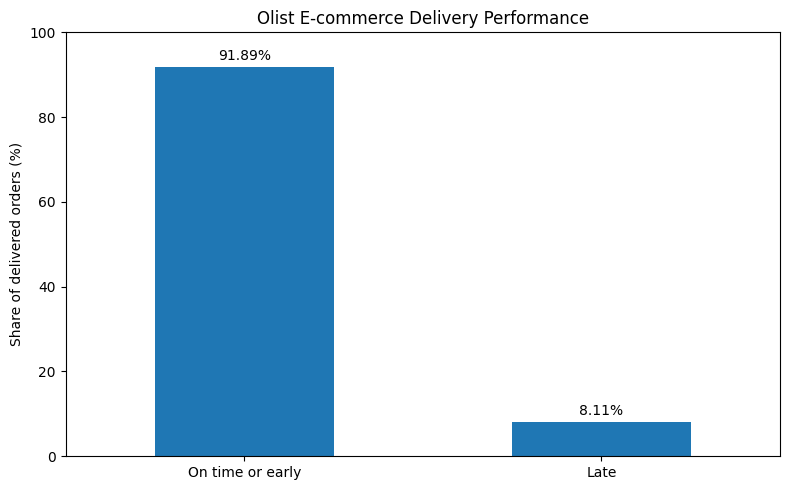

In [5]:

# Create an executive summary chart

metrics = pd.Series({
    "On time or early": on_time_delivery_rate,
    "Late": late_delivery_rate
})

ax = metrics.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Olist E-commerce Delivery Performance")
ax.set_ylabel("Share of delivered orders (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


## 4. Monthly Delivery Performance

This section examines changes in delivery performance by purchase month. The late-delivery rate captures the proportion of orders delayed, while the number of late orders shows the absolute operational volume.

Months with very few orders can produce extreme percentages that are not representative of overall performance. We retain all valid observations in the underlying analysis, but exclude months with fewer than 100 orders from the comparison charts to improve readability.


In [6]:

# Analyze delivery performance by purchase month

delivery_data["purchase_month"] = (
    delivery_data["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_performance = (
    delivery_data.groupby("purchase_month")
    .agg(
        total_orders=("order_id", "count"),
        late_orders=("is_late", "sum"),
        avg_delivery_days=("actual_delivery_days", "mean"),
        avg_delay_days=("delivery_delay_days", "mean")
    )
)

monthly_performance["late_delivery_rate"] = (
    monthly_performance["late_orders"]
    / monthly_performance["total_orders"] * 100
)

monthly_performance = monthly_performance.round(2)

display(monthly_performance.tail(15))


,total_orders,late_orders,avg_delivery_days,avg_delay_days,late_delivery_rate
purchase_month,,,,,
2017-06,3135,121,12.01,-12.01,3.86
2017-07,3872,133,11.59,-11.72,3.43
2017-08,4193,139,11.15,-12.33,3.32
2017-09,4150,216,11.85,-10.59,5.20
2017-10,4478,237,11.86,-11.16,5.29
2017-11,7288,1043,15.16,-7.40,14.31
2017-12,5513,462,15.39,-12.29,8.38
2018-01,7069,464,14.08,-12.22,6.56
2018-02,6555,1048,16.95,-7.58,15.99


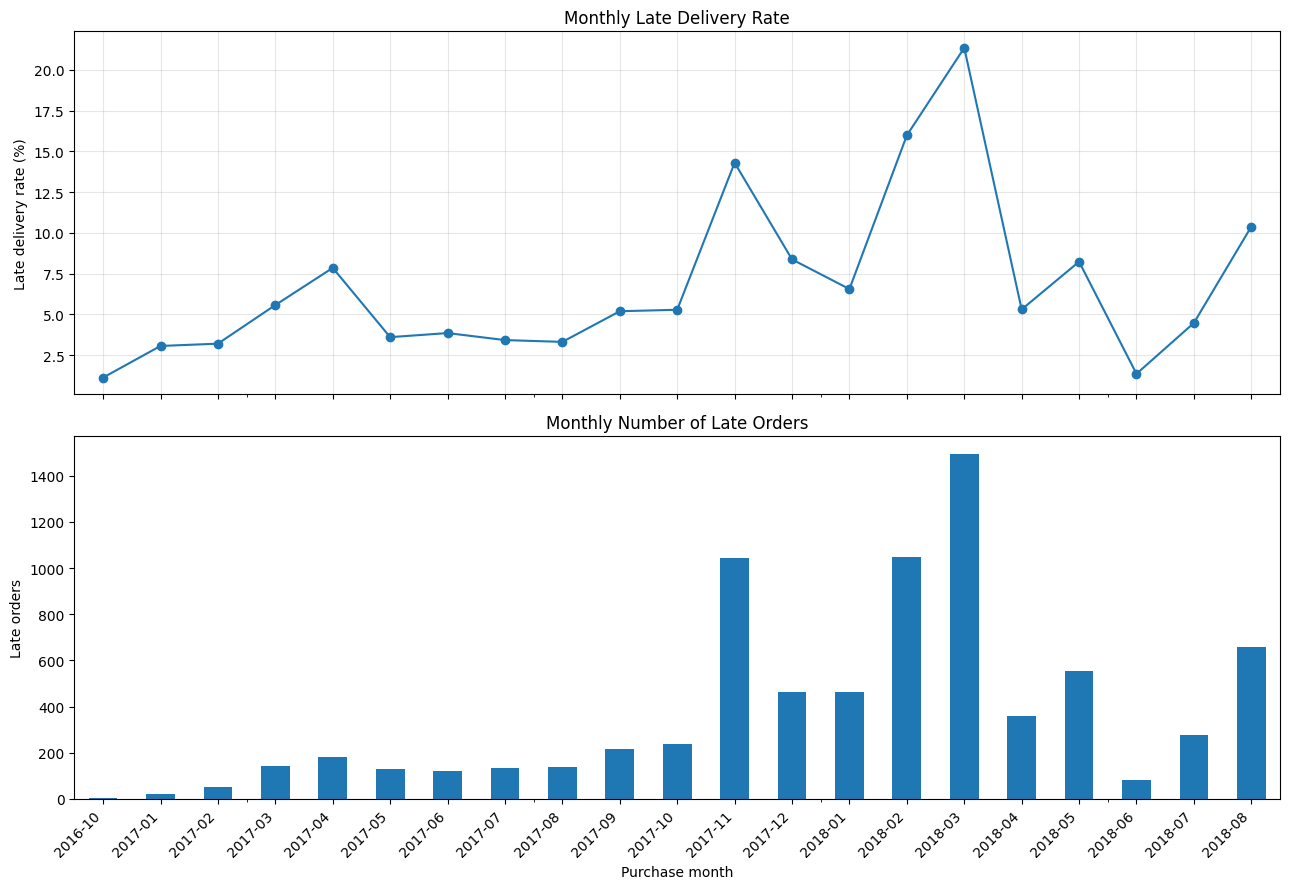

In [7]:
# Filter months with sufficient order volume for comparison
monthly_chart = monthly_performance.loc[
    monthly_performance["total_orders"] >= 100
].copy()

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

monthly_chart["late_delivery_rate"].plot(
    ax=axes[0],
    marker="o"
)
axes[0].set_title("Monthly Late Delivery Rate")
axes[0].set_ylabel("Late delivery rate (%)")
axes[0].set_xlabel("")
axes[0].grid(True, alpha=0.3)

monthly_chart["late_orders"].plot(
    ax=axes[1],
    kind="bar"
)
axes[1].set_title("Monthly Number of Late Orders")
axes[1].set_ylabel("Late orders")
axes[1].set_xlabel("Purchase month")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [8]:
# Identify the five months with the highest late-delivery rates
# among months with at least 100 orders
top_late_months = (
    monthly_performance.loc[monthly_performance["total_orders"] >= 100]
    .sort_values("late_delivery_rate", ascending=False)
    .head(5)
)

display(top_late_months)


,total_orders,late_orders,avg_delivery_days,avg_delay_days,late_delivery_rate
purchase_month,,,,,
2018-03,7003,1496,16.30,-5.73,21.36
2018-02,6555,1048,16.95,-7.58,15.99
2017-11,7288,1043,15.16,-7.40,14.31
2018-08,6351,660,7.73,-7.45,10.39
2017-12,5513,462,15.39,-12.29,8.38


### Key Findings

- March 2018 recorded a late-delivery rate of 21.36%, with 1,496 late orders.
- February 2018 and November 2017 also showed elevated late-delivery rates, at 15.99% and 14.31%, respectively.
- September 2016 recorded a 100% late-delivery rate based on only one order. This observation is not representative of monthly performance and should not be interpreted as a reliable trend.
- Monthly delivery performance varied considerably, suggesting that further analysis is needed to investigate potential operational factors.

### Business Implications

Periods with elevated late-delivery rates could be prioritized for operational investigation. However, these descriptive results do not establish the causes of delays. Further analysis of order approval, carrier handoff, and delivery timelines is required before recommending specific operational changes.


## 5. Operational Timeline Analysis

This section examines the time spent across different stages of the order fulfillment process. Breaking down the timeline helps identify where delays may accumulate and which stages deserve further investigation.

The analysis covers the time from purchase to approval, approval to carrier handoff, and carrier handoff to customer delivery. Results are interpreted as descriptive operational indicators rather than proof of causation.

In [9]:

# Calculate elapsed time across order fulfillment stages

delivery_data["purchase_to_approval_days"] = (
    delivery_data["order_approved_at"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery_data["approval_to_carrier_days"] = (
    delivery_data["order_delivered_carrier_date"]
    - delivery_data["order_approved_at"]
).dt.total_seconds() / 86400

delivery_data["carrier_to_customer_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

stage_columns = [
    "purchase_to_approval_days",
    "approval_to_carrier_days",
    "carrier_to_customer_days"
]

stage_summary = (
    delivery_data[stage_columns]
    .describe()
    .T[["count", "mean", "50%", "75%", "max"]]
    .rename(columns={"50%": "median_days", "75%": "p75_days"})
    .round(2)
)

display(stage_summary)


,count,mean,median_days,p75_days,max
purchase_to_approval_days,96456.0,0.43,0.01,0.60,30.89
approval_to_carrier_days,96455.0,2.80,1.82,3.57,125.76
carrier_to_customer_days,96469.0,9.33,7.10,12.03,205.19


### 5.1 Fulfillment Stage Duration

The following comparison examines the mean and median duration of each fulfillment stage. Comparing both statistics helps identify stages with long typical durations and stages where extreme observations may influence the average.

The results describe elapsed time between recorded timestamps and should not be interpreted as proof of operational responsibility.

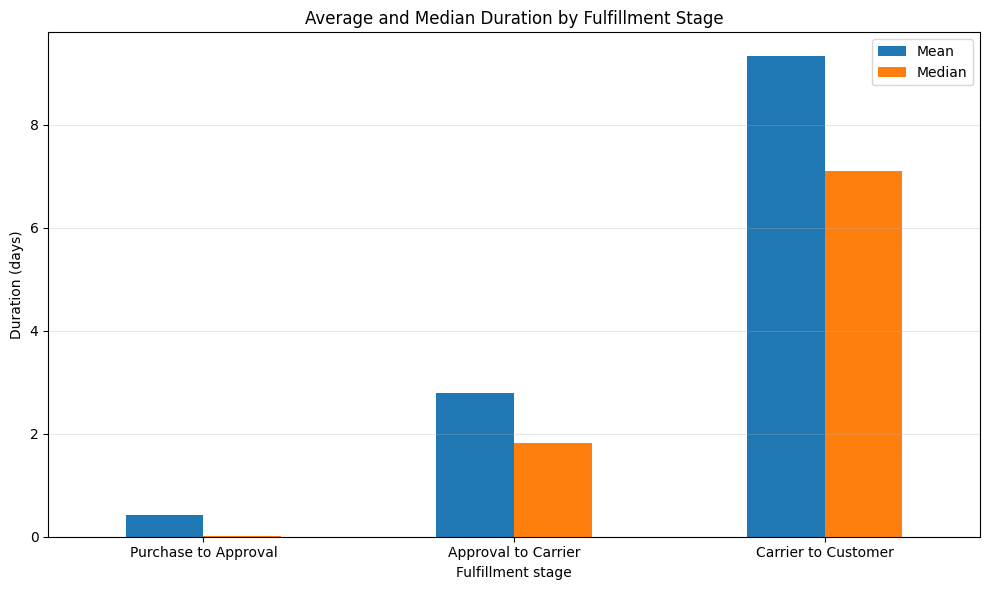

In [10]:

# Compare mean and median duration across fulfillment stages

stage_labels = {
    "purchase_to_approval_days": "Purchase to Approval",
    "approval_to_carrier_days": "Approval to Carrier",
    "carrier_to_customer_days": "Carrier to Customer"
}

stage_plot_data = delivery_data[stage_columns].rename(
    columns=stage_labels
)

stage_comparison = pd.DataFrame({
    "Mean": stage_plot_data.mean(),
    "Median": stage_plot_data.median()
})

ax = stage_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("Average and Median Duration by Fulfillment Stage")
ax.set_ylabel("Duration (days)")
ax.set_xlabel("Fulfillment stage")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### 5.2 Data Quality Assessment for Fulfillment Timelines

Before interpreting operational durations, we assess missing timestamps, negative intervals, and unusually long stage durations. Negative intervals indicate that recorded timestamps are not chronologically consistent for the calculated stage.

These records are flagged for further review rather than automatically treated as errors. Long durations are also retained initially because they may represent genuine delivery delays.

In [11]:

# Inspect potentially unusual fulfillment stage durations

stage_quality = pd.DataFrame({
    "missing_values": delivery_data[stage_columns].isna().sum(),
    "negative_durations": (delivery_data[stage_columns] < 0).sum(),
    "over_30_days": (delivery_data[stage_columns] > 30).sum()
})

display(stage_quality)


,missing_values,negative_durations,over_30_days
purchase_to_approval_days,14,0,2
approval_to_carrier_days,15,1350,177
carrier_to_customer_days,1,23,2686


In [12]:

# Quantify timeline inconsistencies and long durations

timeline_quality = pd.DataFrame({
    "missing": delivery_data[stage_columns].isna().sum(),
    "negative": (delivery_data[stage_columns] < 0).sum(),
    "over_30_days": (delivery_data[stage_columns] > 30).sum()
})

display(timeline_quality)

# Compare stage duration statistics before and after excluding negative intervals
stage_quality_comparison = []

for column in stage_columns:
    valid_values = delivery_data[column].dropna()
    nonnegative_values = valid_values[valid_values >= 0]

    stage_quality_comparison.append({
        "stage": column,
        "mean_all_valid": valid_values.mean(),
        "median_all_valid": valid_values.median(),
        "mean_nonnegative": nonnegative_values.mean(),
        "median_nonnegative": nonnegative_values.median(),
        "negative_records_excluded": int((valid_values < 0).sum())
    })

stage_quality_comparison = pd.DataFrame(stage_quality_comparison).round(2)

display(stage_quality_comparison)


,missing,negative,over_30_days
purchase_to_approval_days,14,0,2
approval_to_carrier_days,15,1350,177
carrier_to_customer_days,1,23,2686


,stage,mean_all_valid,median_all_valid,mean_nonnegative,median_nonnegative,negative_records_excluded
0,purchase_to_approval_days,0.43,0.01,0.43,0.01,0
1,approval_to_carrier_days,2.80,1.82,2.85,1.85,1350
2,carrier_to_customer_days,9.33,7.10,9.33,7.10,23


### 5.3 Data Quality Findings

The timeline assessment identified 1,350 negative intervals between order approval and carrier handoff, indicating inconsistencies in the recorded timestamps for this stage. Only 23 negative intervals were identified between carrier handoff and customer delivery.

Excluding negative intervals for sensitivity analysis had little effect on the median duration of each stage. For approval-to-carrier time, the median increased from 1.82 to 1.85 days, while the mean increased from 2.80 to 2.85 days.

Long durations were retained because they may represent genuine operational delays. These findings highlight the importance of validating timestamp consistency before using operational metrics to guide decisions.

## 6. Operational Factors Associated with Late Deliveries

This section compares fulfillment stage durations between late and on-time or early orders. The objective is to identify operational patterns that may warrant further investigation.

Because timestamp inconsistencies exist, negative stage durations are treated as missing for this comparison. Long positive durations are retained, as they may reflect genuine delivery delays. The comparison is descriptive and does not establish causation.

In [13]:

# Prepare stage durations for comparison
stage_columns = [
    "purchase_to_approval_days",
    "approval_to_carrier_days",
    "carrier_to_customer_days"
]

stage_labels = {
    "purchase_to_approval_days": "Purchase to Approval",
    "approval_to_carrier_days": "Approval to Carrier",
    "carrier_to_customer_days": "Carrier to Customer"
}

# Treat negative stage durations as missing for this comparison
stage_analysis = delivery_data[stage_columns].where(
    delivery_data[stage_columns] >= 0
)

stage_analysis = stage_analysis.rename(columns=stage_labels)
stage_analysis["delivery_status"] = delivery_data["is_late"].map({
    True: "Late",
    False: "On time or early"
})

stage_comparison_by_status = (
    stage_analysis.groupby("delivery_status")
    .agg(["mean", "median"])
    .round(2)
)

display(stage_comparison_by_status)


Purchase to Approval        Approval to Carrier         \
                                 mean median                mean median   
delivery_status                                                           
Late                             0.51   0.02                5.35   3.02   
On time or early                 0.42   0.01                2.63   1.78   

                 Carrier to Customer         
                                mean median  
delivery_status                              
Late                           25.68  23.92  
On time or early                7.89   6.92

### 6.1 Fulfillment Duration by Delivery Status

Comparing stage durations across delivery outcomes helps quantify where the largest differences occur between late and on-time or early orders.

The comparison is descriptive: longer durations may be associated with late delivery, but the results alone do not establish causation.

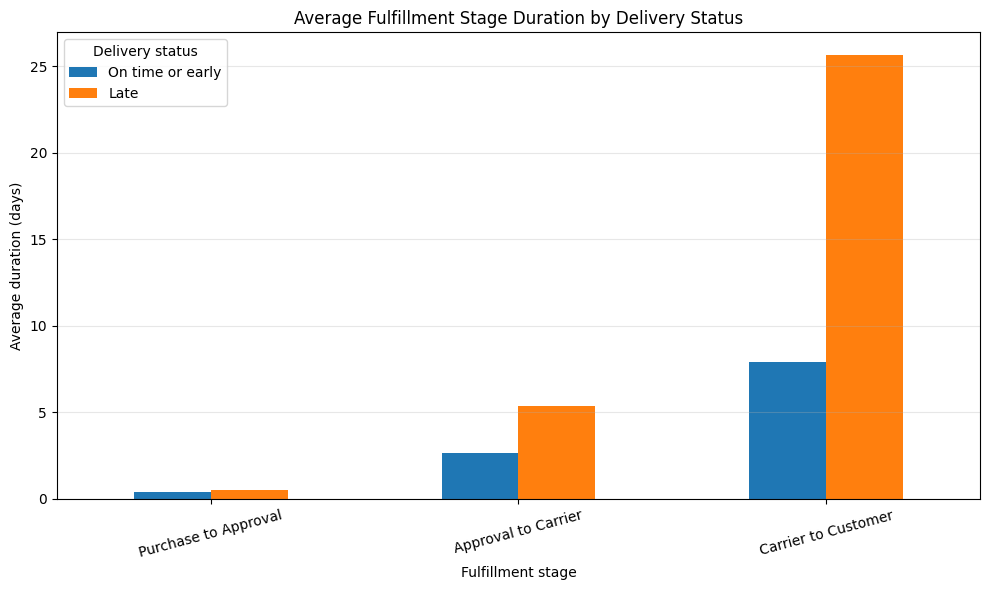

In [14]:

# Compare mean stage duration by delivery status

stage_means = (
    stage_analysis
    .groupby("delivery_status")[list(stage_labels.values())]
    .mean()
    .reindex(["On time or early", "Late"])
)

ax = stage_means.T.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("Average Fulfillment Stage Duration by Delivery Status")
ax.set_ylabel("Average duration (days)")
ax.set_xlabel("Fulfillment stage")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Delivery status")

plt.tight_layout()
plt.show()



### 6.2 Key Findings and Business Implications

- **Carrier to Customer:** Late orders took an average of 25.68 days, compared with 7.89 days for on-time or early orders. This is the largest observed difference across the three stages.
- **Approval to Carrier:** Late orders averaged 5.35 days, compared with 2.63 days for on-time or early orders.
- **Purchase to Approval:** The difference was comparatively small, with averages of 0.51 and 0.42 days, respectively.

These associations identify stages for further investigation but do not prove that longer stage durations cause late delivery or establish responsibility for a specific logistics provider.

Operational teams could prioritize the post-dispatch stage for further investigation, including route performance, geographic differences, and delivery exceptions. The approval-to-carrier stage is another potential improvement area.

Before recommending operational changes, these patterns should be validated across regions, time periods, and order characteristics.


## 7. Geographic Delivery Performance

This section examines delivery performance across customer states in Brazil. It compares the number of delivered orders and late-delivery rates by state to identify geographic areas that may warrant further investigation.

Both order volume and late-delivery rate are considered because states with high volumes may contribute many late orders even when their delay rate is moderate.

In [15]:

# Load customer location data
customers = pd.read_csv(dataset_path / "olist_customers_dataset.csv")

# Join delivered orders with customer states
geographic_data = delivery_data.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Summarize delivery performance by customer state
state_performance = (
    geographic_data.groupby("customer_state")
    .agg(
        total_orders=("order_id", "count"),
        late_orders=("is_late", "sum")
    )
)

state_performance["late_delivery_rate"] = (
    state_performance["late_orders"]
    / state_performance["total_orders"] * 100
)

state_performance = state_performance.sort_values(
    "late_delivery_rate",
    ascending=False
).round(2)

display(state_performance)


,total_orders,late_orders,late_delivery_rate
customer_state,,,
AL,397,95,23.93
MA,717,141,19.67
PI,476,76,15.97
CE,1279,196,15.32
SE,335,51,15.22
BA,3256,457,14.04
RJ,12350,1664,13.47
TO,274,35,12.77
PA,946,117,12.37


### 7.1 Geographic Differences in Delivery Performance

Delivery performance varies across customer states. Comparing late-delivery rates helps identify areas with potentially elevated risk, while late-order counts reveal where the largest operational volumes occur.

To make comparisons more reliable, the rate ranking excludes states with fewer than 100 delivered orders. This is a reporting threshold, not a statistical significance test.

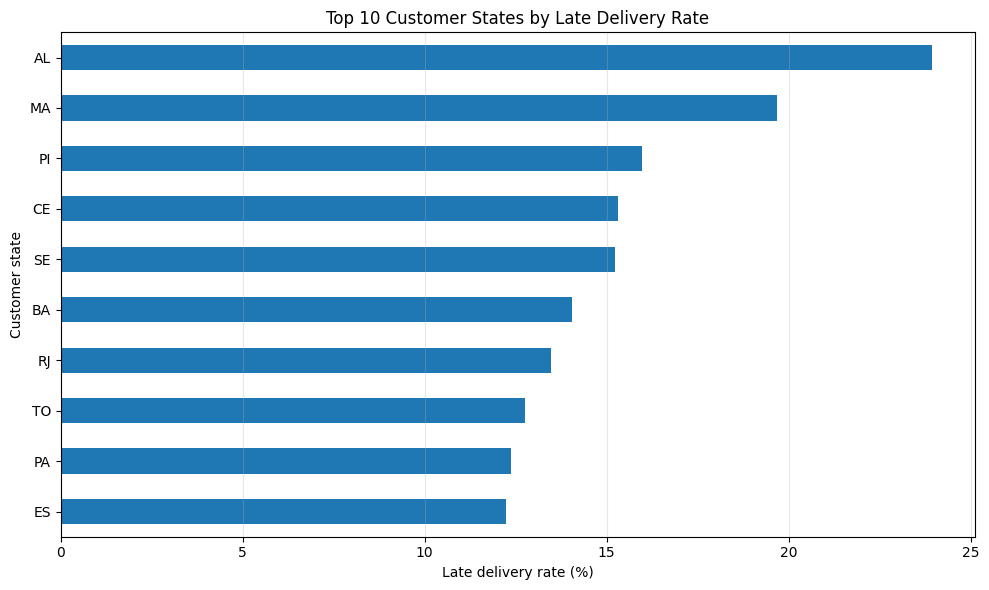

In [16]:

# Rank states by late-delivery rate, excluding low-volume states
state_chart = (
    state_performance.loc[state_performance["total_orders"] >= 100]
    .sort_values("late_delivery_rate", ascending=False)
    .head(10)
    .sort_values("late_delivery_rate")
)

ax = state_chart["late_delivery_rate"].plot(
    kind="barh",
    figsize=(10, 6)
)

ax.set_title("Top 10 Customer States by Late Delivery Rate")
ax.set_xlabel("Late delivery rate (%)")
ax.set_ylabel("Customer state")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


In [17]:

# Identify states with the highest number of late orders
top_states_by_late_volume = (
    state_performance
    .sort_values("late_orders", ascending=False)
    .head(10)
)

display(top_states_by_late_volume)


,total_orders,late_orders,late_delivery_rate
customer_state,,,
SP,40494,2387,5.89
RJ,12350,1664,13.47
MG,11354,637,5.61
BA,3256,457,14.04
RS,5344,382,7.15
SC,3546,346,9.76
PR,4923,246,5.00
ES,1995,244,12.23
CE,1279,196,15.32


### 7.2 Geographic Findings

- Alagoas (AL) recorded the highest late-delivery rate among states with at least 100 delivered orders, at 23.93%, based on 397 orders.
- Maranhão (MA) and Piauí (PI) also showed elevated late-delivery rates, at 19.67% and 15.97%, respectively.
- São Paulo (SP) recorded the highest absolute number of late orders, with 2,387 late deliveries out of 40,494 orders, corresponding to a 5.89% late-delivery rate.
- Rio de Janeiro (RJ) recorded 1,664 late orders and a 13.47% late-delivery rate.

### Business Implications

Geographic prioritization should consider both late-delivery rates and absolute late-order volumes. States with elevated rates may warrant investigation into local delivery conditions, while high-volume states may offer opportunities to reduce a larger number of late deliveries.

These results are descriptive. Differences across states do not establish the causes of late deliveries, and comparisons should account for differences in order volume and customer geography.

## 8. Conclusions and Recommendations

### Key Conclusions

1. **Overall delivery performance:** 8.11% of analyzed delivered orders arrived after the estimated delivery date, while 91.89% arrived on time or early.
2. **Monthly variation:** Late-delivery rates varied substantially across purchase months. March 2018 recorded a 21.36% rate, based on 7,003 delivered orders.
3. **Fulfillment timeline:** The carrier-to-customer stage showed the largest difference between late and on-time or early orders, with mean durations of 25.68 and 7.89 days, respectively.
4. **Geographic variation:** Some states showed elevated late-delivery rates, while São Paulo accounted for the largest absolute number of late orders.
5. **Data quality:** Negative and unusually long stage durations highlight the importance of validating timestamps before using operational metrics.

### Recommendations

- **Investigate post-dispatch delivery:** Examine routes, delivery exceptions, and regional patterns to understand the large difference in carrier-to-customer duration.
- **Prioritize by both rate and volume:** Review high-rate states and high-volume states separately to balance service improvement and operational impact.
- **Monitor monthly performance:** Track late-delivery rates and late-order counts together, using consistent definitions and sufficient sample sizes.
- **Improve timestamp quality:** Investigate inconsistent event sequences and document data-quality limitations in operational reports.
- **Validate before intervention:** Compare findings across time periods, regions, and order characteristics before attributing delays to a particular operational factor.

### Limitations

This analysis uses historical delivered orders from the Olist dataset. It excludes delivered-status records without usable actual delivery timestamps from delivery-performance calculations. The findings are descriptive and do not establish causality. Timestamp inconsistencies and extreme durations may affect some operational measures.

### Next Steps

Future work could incorporate seller location, freight value, product characteristics, and delivery distance proxies. A predictive model should only be developed after defining a realistic prediction point and ensuring that all input variables would be available at that time.